In [443]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

In [444]:
pi_t = 0.35368326100748115
tau_t = 0.7687676014665914
eta_t = 0.90
pi_d =  0.989163
pi_b = 1

m_dot_fR = 0.008726071272118822

A1 = 0.00318
A4 = 0.0005141364620689669
A8 = 0.0012745633749949147
M4 = 1
M8 = 1

In [445]:
tau_d = 1

In [446]:
pi_c_max = 18
pi_c_min = 7.5

rpm_max = 66000

Tt4_max = 1800

In [447]:
gamma = 1.4
Gamma = (2/(gamma+1))**((gamma+1)/(2*(gamma-1)))*np.sqrt(gamma)
Cp = 1004.5
R = 287
h = 4.45e+7

Alt_list = np.array([0,4000,8000,12000])
T0_list = np.array([288.15 ,262.15 ,236.23 ,216.65])
P0_list = np.array([101325 , 61640.235,35651 ,19330.405])
rho0_list = P0_list/(R*T0_list)
a0_list = np.sqrt(gamma*R*T0_list)



C:\Users\rjk12\AppData\Local\Temp\ipykernel_36812\118410524.py:83: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  Tt4 = scipy.optimize.fsolve(_mdotf,Tt4_guess,maxfev=90000)[0]


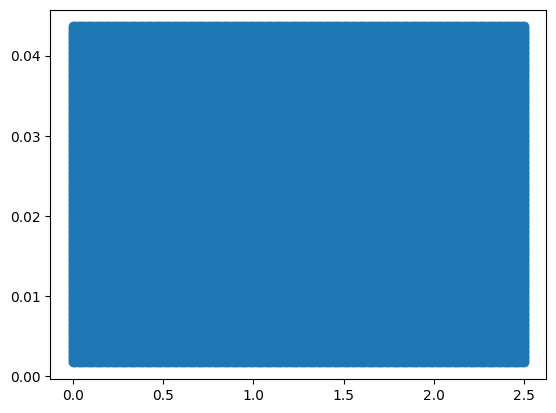

In [448]:
n = 200
Alt_size = Alt_list.size

M0 = np.linspace(0,2.5,n)
m_dot_f = np.linspace(.2,5,n) * m_dot_fR

M0, m_dot_f = np.meshgrid(M0,m_dot_f)

plt.scatter(M0,m_dot_f)

# plt.xlabel('Mach')
# plt.ylabel(r'$\dot{m}_f$')
# plt.tight_layout()
# plt.savefig(r'test_points.png', dpi=1200)

M0 = np.matrix.flatten(M0)
m_dot_f = np.matrix.flatten(m_dot_f)


#M0 = np.array([0.85])
#m_dot_f =  np.array([m_dot_fR]) 

j = 3

Alt = Alt_list[j]
T0 = T0_list[j]
P0 = P0_list[j]
rho0 = P0/(R*T0)
a0 = np.sqrt(gamma*R*T0)


Tt4_plot = np.zeros(n**2)
rpm_plot = np.zeros(n**2)
pi_c_plot = np.zeros(n**2)
Thrust_plot = np.zeros(n**2)
spill_plot = np.zeros(n**2)


def eta_c_fit(Tt4):
        x = Tt4/Tt2
        a = -2.3219 
        b = 1.7094 
        c = -0.2897 
        d = 0.0155
        return a + b*x + c*x**2 + d*x**3

def corr_pm_fit(pi_c):
    x = pi_c
    aa = 22352.47 
    bb = 3718.445 
    cc = -52.5576 
    dd = -1.0899
    return aa + bb*x + cc*x**2 + dd*x**3

def _tau_c(Tt4):
    return 1+(Tt4/Tt0)*(1-tau_t)

def _pi_c(Tt4):
    return  (1+eta_c_fit(Tt4)*(_tau_c(Tt4)-1))**(gamma/(gamma-1))

def _m_dot(Tt4):
    return Gamma / np.sqrt(R) * A4 * (P0*pi_r*pi_d*_pi_c(Tt4)*pi_b)*1/(np.sqrt(Tt4))

def _mdotf(Tt4):
    return _m_dot(Tt4)*Cp*(Tt4 - _tau_c(Tt4) * Tt2)/h-m_dot_f[i]


for i in range(M0.size):
    u0 = M0[i] * np.sqrt(gamma*R*T0)
    
    m_dot_no_spill = rho0 * u0 * A1
    
    tau_r = 1+(gamma-1)/2 * M0[i]**2
    pi_r = tau_r**(gamma/(gamma-1))
    
    Tt0 = T0 * tau_r
    Pt0 = P0 * pi_r
    
    Tt2 = Tt0
    Pt2 = Pt0 * pi_d
    
    Tt4_guess = 800
    Tt4 = scipy.optimize.fsolve(_mdotf,Tt4_guess,maxfev=90000)[0]
    
    tau_c = _tau_c(Tt4)
    pi_c = _pi_c(Tt4)

    m_dot_air = _m_dot(Tt4)
    corr_rpm = corr_rpm_fit(pi_c)# np.sqrt(Tt0/T0)
    
    eta_c = eta_c_fit(Tt4)
    
    
    Tt8 = Tt4 * tau_t
    Pt8 = Pt2 * pi_c * pi_b * pi_t
    
    T8 = Tt8 / (1 + (gamma-1)/2 * M8**2)
    P8 = Pt8 / (1 + (gamma-1)/2 * M8**2)**(gamma/(gamma-1))
    
    u8 = M8 * np.sqrt(gamma*R*T8)
    
    
    
    Tt4_plot[i] = Tt4
    rpm_plot[i] = corr_rpm
    pi_c_plot[i] = pi_c
    spill_plot[i] = (m_dot_no_spill-m_dot_air)
    Thrust_plot[i] = (m_dot_air) * (u8 - u0) + (P8 - P0) * A8
    
    
    if Tt4 > Tt4_max or Tt4 <= Tt0 or Tt4 == Tt4_guess or pi_c > pi_c_max or pi_c < pi_c_min or corr_rpm > rpm_max:
        Tt4_plot[i] = np.nan
        pi_c_plot[i] = np.nan
        rpm_plot[i] = np.nan
        Thrust_plot[i] = np.nan
        spill_plot[i] = np.nan
        continue

In [449]:
Tt4_plot = np.reshape(Tt4_plot,(n,n))
rpm_plot = np.reshape(rpm_plot,(n,n))
pi_c_plot = np.reshape(pi_c_plot,(n,n))
spill_plot = np.reshape(spill_plot,(n,n))
Thrust_plot = np.reshape(Thrust_plot,(n,n))
M0 = np.reshape(M0,(n,n))
m_dot_f = np.reshape(m_dot_f,(n,n))

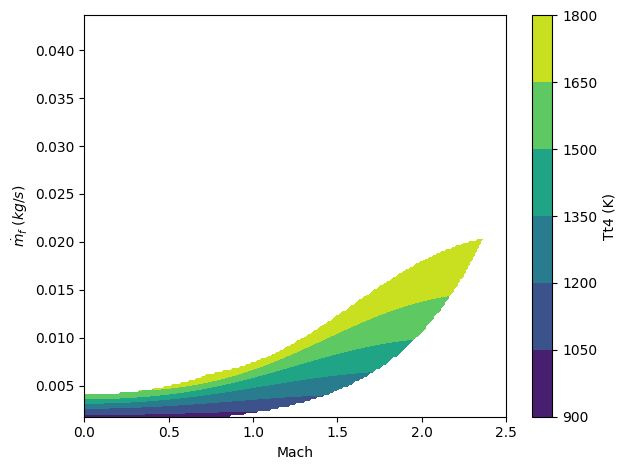

In [450]:
fig = plt.figure(1)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,Tt4_plot)
cbar = fig.colorbar(cp)
cbar.ax.set_ylabel(r'Tt4 (K)')

if j == 2:
    ax.scatter(0.85,m_dot_fR,c='k',marker='x')
    
# ax.set_title(r'$Tt4$ (K) at {} m '.format(Alt_list[j]))
ax.set_xlabel('Mach')
ax.set_ylabel(r'$\dot{m}_f \ (kg/s)$')
plt.tight_layout()
plt.savefig(r'{}_m_Tt4.png'.format(Alt_list[j]), dpi=1200)
plt.show()

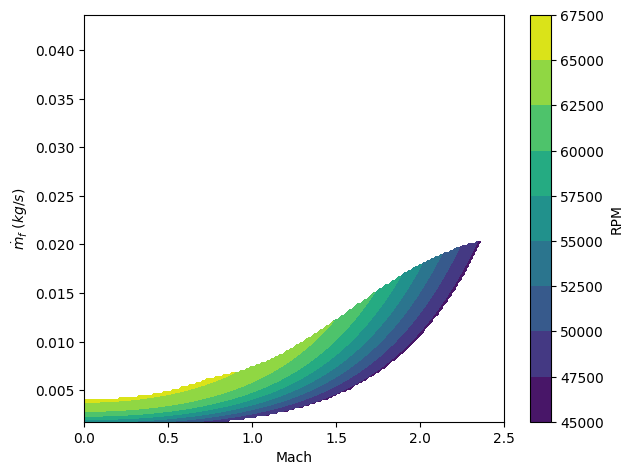

In [451]:
fig = plt.figure(2)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,rpm_plot,cmap='viridis')

if j == 2:
    ax.scatter(0.85,m_dot_fR,c='k',marker='x')

# ax.set_title(r'Turbo-Machinery RPM at {} m '.format(Alt_list[j]))
ax.set_xlabel('Mach')
ax.set_ylabel(r'$\dot{m}_f \ (kg/s)$')
plt.tight_layout()
cbar = fig.colorbar(cp)
cbar.ax.set_ylabel('RPM')
plt.savefig(r'{}_m_rpm.png'.format(Alt_list[j]), dpi=1200)
plt.show()

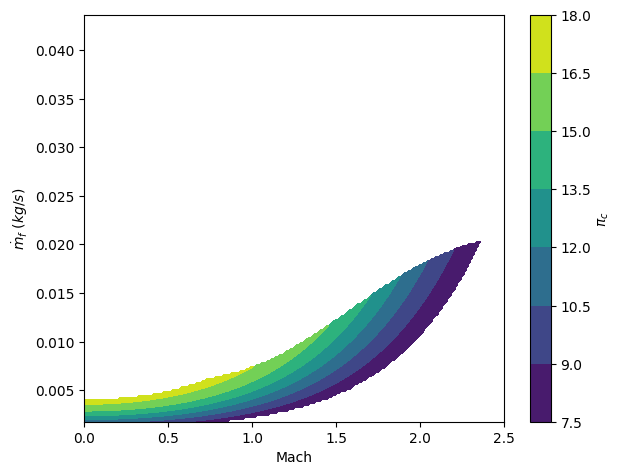

In [452]:
fig = plt.figure(3)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,pi_c_plot)

if j == 2:
    ax.scatter(0.85,m_dot_fR,c='k',marker='x')
    
# ax.set_title(r'$\pi_c$ at {} m '.format(Alt_list[j]))
ax.set_xlabel('Mach')
ax.set_ylabel(r'$\dot{m}_f \ (kg/s)$')
plt.tight_layout()
cbar = fig.colorbar(cp)
cbar.ax.set_ylabel(r'$\pi_c$')
plt.savefig(r'{}_m_pic.png'.format(Alt_list[j]), dpi=1200)
plt.show()

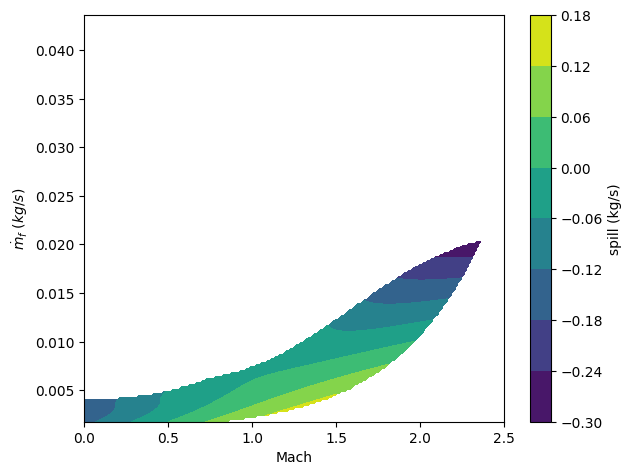

In [453]:
fig = plt.figure(4)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,spill_plot)

if j == 2:
    ax.scatter(0.85,m_dot_fR,c='k',marker='x')
    
# ax.set_title(r'spill (kg/s) at {} m '.format(Alt_list[j]))
ax.set_xlabel('Mach')
ax.set_ylabel(r'$\dot{m}_f \ (kg/s)$')
plt.tight_layout()
cbar = fig.colorbar(cp)
cbar.ax.set_ylabel(r'spill (kg/s)')
plt.savefig(r'{}_m_spill.png'.format(Alt_list[j]), dpi=1200)
plt.show()

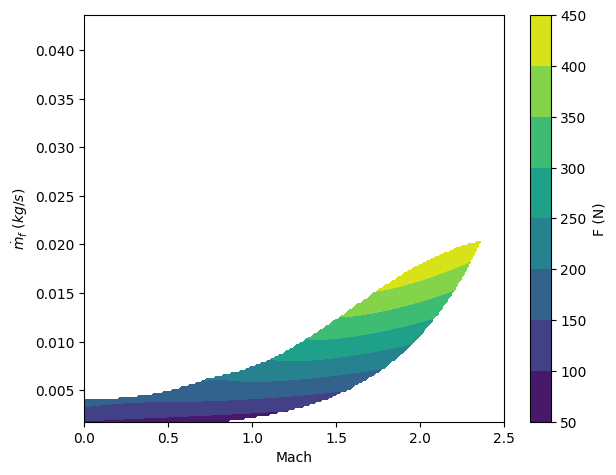

In [454]:
fig = plt.figure(5)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,Thrust_plot)

if j == 2:
    ax.scatter(0.85,m_dot_fR,c='k',marker='x')
    
# ax.set_title(r'Thrust (N) at {} m '.format(Alt_list[j]))
ax.set_xlabel('Mach')
ax.set_ylabel(r'$\dot{m}_f \ (kg/s)$')
plt.tight_layout()
cbar = fig.colorbar(cp)
cbar.ax.set_ylabel(r'F (N)')
plt.savefig(r'{}_m_thrust.png'.format(Alt_list[j]), dpi=1200)
plt.show()